Sara Rezaei

In [ ]:
import torch
from torch.utils.data import DataLoader, Dataset
import torchvision
import torchvision.transforms as transforms
from torch.utils.data.sampler import SubsetRandomSampler
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
#set gpu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


FashionMNIST dataset is ready to use in torch visions datasets and it can be imported directly from the library.

In [ ]:
train_set = torchvision.datasets.FashionMNIST("./data", download=True, train=True,
                                              transform=transforms.Compose([transforms.ToTensor()]))
test_set = torchvision.datasets.FashionMNIST("./data", download=True, train=False,
                                             transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 26.4M/26.4M [00:00<00:00, 117MB/s]


Extracting ./data/FashionMNIST/raw/train-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 29.5k/29.5k [00:00<00:00, 6.43MB/s]


Extracting ./data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 4.42M/4.42M [00:00<00:00, 63.6MB/s]


Extracting ./data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 5.15k/5.15k [00:00<00:00, 7.07MB/s]


Extracting ./data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



splitting dataset to train set and valid set using random split

In [ ]:
batch_size = 32
train_loader = DataLoader(train_set, batch_size=batch_size , shuffle = True)
test_loader = DataLoader(test_set, batch_size=batch_size , shuffle = False)

In [ ]:
print("The train set contains {} images, in {} batches".format(len(train_loader), len(train_loader)))
print("The test set contains {} images, in {} batches".format(len(test_loader), len(test_loader)))

The train set contains 1875 images, in 1875 batches
The test set contains 313 images, in 313 batches


Visualize Dataset

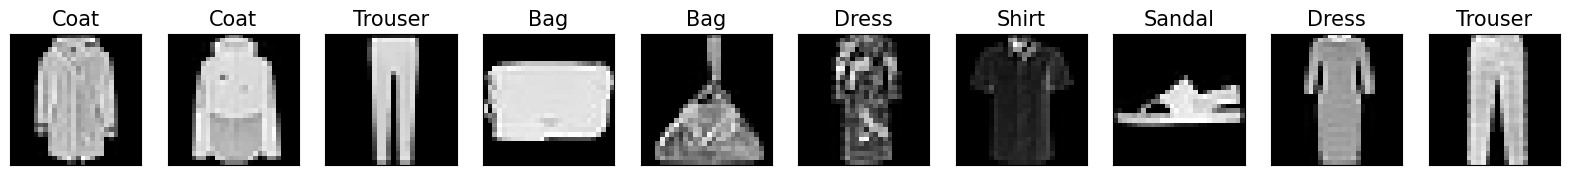

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

nsamples=10
classes_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal','Shirt', 'Sneaker', 'Bag', 'Ankle boot']
imgs, labels = next(iter(train_loader))

fig=plt.figure(figsize=(20,5),facecolor='w')
for i in range(nsamples):
    ax = plt.subplot(1,nsamples, i+1)
    plt.imshow(imgs[i, 0, :, :], vmin=0, vmax=1.0, cmap=cm.gray)
    ax.set_title("{}".format(classes_names[labels[i]]), fontsize=15)
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.savefig('fashionMNIST_samples.png', bbox_inches='tight')
plt.show()

**Initialize the arguments**


in this part I set input_size and num_classes so it can be used as the models inputs.

I set epochs = 30 as the models are not so complicated.

and the learning rate will be 0.001.

In [ ]:
input_size = 28 * 28
num_classes = 10
epochs = 30
lr = 1e-3

In [ ]:
class Discriminator(nn.Module):
  def __init__(self):
    super().__init__()
    self.flat =nn.Flatten()
    self.dis_model=nn.Sequential(
        nn.Linear(784, 1024),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(1024, 512),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(512, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, 1),
        nn.Sigmoid()
    )

  def forward(self, x):
    x=self.flat(x)
    out=self.dis_model(x)
    return out

In [ ]:
discriminate =Discriminator().to(device)

In [ ]:
class Generator(nn.Module):
  def __init__(self):
    super().__init__()
    self.gen_model=nn.Sequential(
        nn.Linear(100, 256),
        nn.ReLU(),
        nn.Linear(256, 512),
        nn.ReLU(),
        nn.Linear(512, 1024),
        nn.ReLU(),
        nn.Linear(1024, 784),
        nn.Tanh()
    )


  def forward(self, x):
    out=self.gen_model(x)
    out=out.view(x.size(0), 1, 28, 28)
    return out

In [ ]:
generator =Generator().to(device)

In [ ]:
loss_function =nn.BCELoss()

optim_gen= torch.optim.Adam(generator.parameters(), lr=lr)
optim_dis= torch.optim.Adam(discriminate.parameters(), lr=lr)

**Train Model**

In [ ]:
for epoch in range(epochs):

  for n, (input_data, labels) in enumerate(train_loader):

    input_data =input_data.to(device)
    # create ones for labels of the discriminator i.e. binary 1 for real 0 for fake
    input_labels=torch.ones((batch_size,1)).to(device)
    #create noise as the input data for the first instance
    noise = torch.randn((batch_size, 100)).to(device)
    fake_labels=torch.zeros((batch_size,1)).to(device)
    # Put noise into the generator
    generated_data =  generator(noise)
    #combine real and fake samples and labels for training
    all_data = torch.cat((input_data, generated_data))
    all_labels= torch.cat((input_labels, fake_labels))
    #Training the discriminator
    discriminate.zero_grad()
    discriminate_output=discriminate(all_data)
    loss_discrminate = loss_function(discriminate_output, all_labels)
    loss_discrminate.backward()
    optim_dis.step()

    #data for the generator
    noise = torch.randn((batch_size, 100)).to(device)
    #Training the generrator
    generator.zero_grad()
    generated_output =generator(noise)
    dis_gen_output=discriminate(generated_output)
    loss_generate=loss_function(dis_gen_output, input_labels)
    loss_generate.backward()
    optim_gen.step()

    if n== batch_size-1:
      print(f'Epoch: {epoch+1} Loss Dis: {loss_discrminate}')
      print(f'Epoch: {epoch+1} Loss Gen: {loss_generate}')

Epoch: 1 Loss Dis: 0.5542775392532349
Epoch: 1 Loss Gen: 0.558130145072937
Epoch: 2 Loss Dis: 0.7221060991287231
Epoch: 2 Loss Gen: 0.9631273150444031
Epoch: 3 Loss Dis: 0.6545473337173462
Epoch: 3 Loss Gen: 0.7170422077178955
Epoch: 4 Loss Dis: 0.6934713125228882
Epoch: 4 Loss Gen: 0.718814492225647
Epoch: 5 Loss Dis: 0.5717567801475525
Epoch: 5 Loss Gen: 0.813421368598938
Epoch: 6 Loss Dis: 0.5391058325767517
Epoch: 6 Loss Gen: 1.4103798866271973
Epoch: 7 Loss Dis: 0.38416004180908203
Epoch: 7 Loss Gen: 2.872230052947998
Epoch: 8 Loss Dis: 0.4766896963119507
Epoch: 8 Loss Gen: 1.2224173545837402
Epoch: 9 Loss Dis: 0.4595925807952881
Epoch: 9 Loss Gen: 1.2216007709503174
Epoch: 10 Loss Dis: 0.5129425525665283
Epoch: 10 Loss Gen: 1.2773029804229736
Epoch: 11 Loss Dis: 0.4452448785305023
Epoch: 11 Loss Gen: 1.343646764755249
Epoch: 12 Loss Dis: 0.41158178448677063
Epoch: 12 Loss Gen: 1.461641550064087
Epoch: 13 Loss Dis: 0.42449474334716797
Epoch: 13 Loss Gen: 1.3694175481796265
Epoch: 

**Test Model**

In [ ]:
noise= torch.randn((batch_size , 100)).to(device)
generated_data = generator(noise)

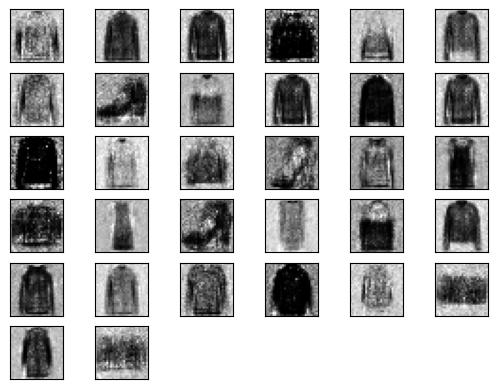

In [ ]:
generated_data = generated_data.cpu().detach()

for i in range(32):
    ax = plt.subplot(6, 6, i + 1)
    plt.imshow(generated_data[i].squeeze(), cmap="gray_r")
    plt.xticks([])
    plt.yticks([])